# Session 5 Research Report
## Cross-Sectional Crypto & Microstructure — the Binance-Vision Pivot

**Date:** 2026-06-06
**Venue target:** Crypto Fund Trader, 2-Phase Evaluation (static 10% max loss, 5% daily, 8%→5% targets, no time limit)
**Goal:** find a crypto edge on **free Binance data** that can pass a crypto-prop challenge with >50% probability.

**The story of this session in one line:** the data unlock is real (taker volume + funding give us signals OHLC can't),
the cross-sectional construction works *in-sample* (2021–23 Sharpe >1), but it is **regime-dependent** and fails
out-of-sample in the 2024–25 BTC-dominance regime. This report documents the math and the failure honestly,
then sets up Path B.


In [1]:
import sys
from pathlib import Path
ROOT = Path().resolve().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from quantresearch.data.binance_loader import load_klines, load_funding
from quantresearch.crypto_xs import build_features, xs_portfolio_returns
from quantresearch.evaluation.ftmo import FTMORules, monte_carlo

pd.set_option('display.width', 110)
def sharpe(x): return x.mean()/x.std()*np.sqrt(252) if x.std()>0 else 0.0
print('Setup OK — all data loads from local data_cache/ (offline, no network).')

Setup OK — all data loads from local data_cache/ (offline, no network).


<a id='1'></a>
## 1. Why this pivot — the constraint that moved

The whole prior project (notebooks 01–04) concluded: **net of real costs (spread + swap), free-retail-data
classical edges cap at ~Sharpe 0.5**, and the binding constraint for a funded challenge is **Calmar**
(return ÷ max-drawdown), not Sharpe. On FTMO the single cost-surviving edge (crypto trend) was strangled by the
**1:1 crypto leverage cap**.

Switching the venue to a **crypto-native prop firm (Crypto Fund Trader)** removes two walls at once:

| Wall on FTMO | On Crypto Fund Trader |
|---|---|
| Crypto leverage capped 1:1 | up to **1:100** |
| Only broker OHLC CFD feed | **715 crypto pairs**, and we can use the raw exchange feed |
| Trailing-style pressure | **static 10%** max loss (2-Phase), no time limit |

And critically: **Binance publishes free historical data at `data.binance.vision`** that includes a field retail
CFD feeds throw away — **taker-buy volume** — letting us reconstruct *signed order flow* and *funding*. That is the
genuine "beyond free retail data" unlock, at zero cost.


<a id='2'></a>
## 2. The data unlock — signed order flow and funding

A Binance kline carries, besides OHLCV, the **taker-buy base volume**: the portion of the bar's volume that was
*aggressive buying* (market orders lifting the offer). Define the **order-flow imbalance**

$$\text{OFI}_t \;=\; \frac{V^{\text{taker-buy}}_t - V^{\text{taker-sell}}_t}{V_t}\;=\; 2\cdot\frac{V^{\text{taker-buy}}_t}{V_t}-1 \;\in[-1,+1].$$

$\text{OFI}=+1$ means every trade in the bar was an aggressive buy; $-1$ all aggressive sells. Plain volume is
*unsigned* and cannot express this — which is structurally why retail OHLC edges were capped.

We also pull the **perpetual funding rate** $f_t$ (8-hourly). Funding is a real cash flow: when $f_t>0$, longs pay
shorts. Its sign and size proxy crowded positioning.


In [2]:
# BTC 15m with taker volume -> OFI
btc = load_klines('BTCUSDT', '15m', '2021-01', '2024-12')
print('BTC 15m bars:', len(btc), '|', btc.index.min(), '->', btc.index.max())
print(btc[['close','volume','taker_buy_ratio','ofi']].describe().loc[['mean','std','min','max']].round(4))

fund = load_funding('BTCUSDT', '2021-01')
print('\nBTC funding: mean = %.5f%%/8h  (~%.1f%%/yr, longs pay shorts on average)'
      % (fund.mean()*100, fund.mean()*3*365*100))

BTC 15m bars: 140256 | 2021-01-01 00:00:00 -> 2024-12-31 23:45:00
            close       volume  taker_buy_ratio     ofi
mean   42589.4678    4105.6120           0.4975 -0.0050
std    18809.2852    5346.3926           0.0720  0.1439
min    15637.9000       0.0000           0.1578 -0.6845
max   108220.3000  171631.0820           0.8891  0.7781

BTC funding: mean = 0.01011%/8h  (~11.1%/yr, longs pay shorts on average)


<a id='3'></a>
## 3. Test #1 — taker-flow imbalance (real but sub-cost)

**Hypothesis:** aggressive buying has a *temporary* price impact that reverts, so OFI is a short-horizon
*contrarian* predictor. We measure the **information coefficient** — the rank (Spearman) correlation between the
signal at $t$ and the forward return over $h$ bars:

$$\text{IC}(h) \;=\; \operatorname{corr}_{\text{rank}}\!\big(\text{signal}_t,\; r_{t\to t+h}\big).$$


In [3]:
c = btc['close']
ofi_ema = btc['ofi'].ewm(span=16).mean()      # smoothed signed flow
print('IC of smoothed OFI vs forward return (15m bars):')
print(f'{"h":>4} {"horizon":>8} {"IC":>9}')
for h,lbl in [(1,'15m'),(2,'30m'),(4,'1h'),(16,'4h'),(96,'1d')]:
    fwd = np.log(c.shift(-h)) - np.log(c)
    d = pd.DataFrame({'s':ofi_ema,'f':fwd}).dropna()
    print(f'{h:>4} {lbl:>8} {d.s.corr(d.f, method="spearman"):>+9.4f}')

# decile $ spread in bps
print('\nForward-return spread (bps) by OFI decile:')
for h,lbl in [(1,'15m'),(4,'1h'),(16,'4h')]:
    fwd_bps = (np.log(c.shift(-h))-np.log(c))*1e4
    d = pd.DataFrame({'s':ofi_ema,'f':fwd_bps}).dropna()
    d['dec'] = pd.qcut(d['s'],10,labels=False)
    m = d.groupby('dec')['f'].mean()
    print(f'  h={lbl:>3}: low-flow {m.iloc[0]:+.2f}  high-flow {m.iloc[-1]:+.2f}  spread {m.iloc[0]-m.iloc[-1]:+.2f} bps')

IC of smoothed OFI vs forward return (15m bars):
   h  horizon        IC


   1      15m   -0.0400
   2      30m   -0.0399
   4       1h   -0.0357


  16       4h   -0.0165
  96       1d   +0.0074

Forward-return spread (bps) by OFI decile:
  h=15m: low-flow +0.45  high-flow +0.39  spread +0.06 bps
  h= 1h: low-flow +0.94  high-flow +1.75  spread -0.81 bps
  h= 4h: low-flow +0.56  high-flow +6.14  spread -5.58 bps


**Reading it.** The IC is genuinely non-zero (~−0.04 at 15m, contrarian, decaying to 0 by a day) — *the
information exists*. But the **dollar** spread between flow deciles is **0–6 bps**, and the crypto fee floor is
**4–10 bps round trip**. The signal is real and **below the cost floor on a single symbol**.

The fix is dictated by the **fundamental law of active management**:

$$\text{IR} \;=\; \text{IC}\cdot\sqrt{\text{breadth}}.$$

A per-symbol IC of 0.04 is hopeless alone, but $\sqrt{\text{breadth}}$ is the lever: run the *same* weak signal
across $N$ coins and the achievable information ratio scales by $\sqrt N$. Microstructure alpha is harvested
**cross-sectionally**, not on one symbol — that motivates §5.


<a id='4'></a>
## 4. Test #2 — funding rate (a trend proxy, not a contrarian signal)

**Hypothesis:** extreme positive funding = crowded longs → price should *revert down* (contrarian, IC < 0).


In [4]:
px8 = c.reindex(c.index.union(fund.index)).interpolate().reindex(fund.index)
F = pd.DataFrame({'fund':fund,'px':px8}).dropna()
F['z'] = (F['fund']-F['fund'].rolling(90).mean())/F['fund'].rolling(90).std()
print('IC of funding vs forward return  (expect NEGATIVE if contrarian):')
print(f'{"k":>4} {"horizon":>8} {"IC_raw":>9} {"IC_zscored":>11}')
for k,lbl in [(1,'8h'),(3,'1d'),(9,'3d'),(21,'7d')]:
    fwd = np.log(F['px'].shift(-k))-np.log(F['px'])
    d = pd.DataFrame({'r':F['fund'],'z':F['z'],'f':fwd}).dropna()
    print(f'{k:>4} {lbl:>8} {d.r.corr(d.f,method="spearman"):>+9.4f} {d.z.corr(d.f,method="spearman"):>+11.4f}')

IC of funding vs forward return  (expect NEGATIVE if contrarian):
   k  horizon    IC_raw  IC_zscored
   1       8h   -0.0189     -0.0345
   3       1d   -0.0378     -0.0488
   9       3d   -0.0376     -0.0380
  21       7d   -0.0256     -0.0071


**Reading it.** Raw funding IC is **positive and grows with horizon** (≈ +0.18 at 7 days) — the *opposite* of
the hypothesis. High funding does not precede reversal; it rides the bull trend. Funding-level is a **momentum /
sentiment proxy** contaminated by the secular uptrend. Z-scoring out the trend collapses the IC to ~0.03 (noise).
The harvestable *carry* (~11%/yr short-side) needs a spot hedge leg we don't have on a one-sided perp account.
**Verdict: not a standalone edge.** Keep funding only as one weak component of a cross-sectional composite.


<a id='5'></a>
## 5. The cross-sectional construction (the math)

For each coin $i$ and bar $t$ we build per-coin signals, then **rank across coins** so only *relative* ranking
matters (absolute market direction cancels). Components:

- **short-term reversal:** $\;\text{rev}_{i,t} = -\sum_{k=1}^{5}\log\frac{P_{i,t-k+1}}{P_{i,t-k}}$ (negative 5-bar return)
- **intermediate momentum:** $\;\text{mom}_{i,t} = \log\frac{P_{i,t-1}}{P_{i,t-481}}$ (≈ 20-day return)
- **funding contrarian:** $\;-\,\text{EWM}_3(f_{i,t})$

Each component is converted to a **cross-sectional z-rank** at every bar,

$$z_{i,t} \;=\; \frac{\operatorname{rank}_i(s_{i,t}) - \overline{\operatorname{rank}}_t}{\sigma\!\left(\operatorname{rank}_t\right)},$$

and the composite is their equal-weight average. We go **long the top $N$ / short the bottom $N$**, equal weight,
rebalanced every `hold_bars`. Portfolio bar-return:

$$r^p_t \;=\; \sum_i w_{i,t-1}\, r_{i,t}, \qquad w_i = \pm\tfrac{1}{N}\ \text{(long/short)},\ \textstyle\sum_i w_i = 0 .$$

**Costs are turnover-based** (charged only on the notional that actually changes), which matters enormously for a
sticky momentum book:

$$\text{cost}_t \;=\; c \cdot \tfrac12\sum_i \big| w_{i,t}-w_{i,t-1}\big|, \qquad c = \text{spread (bps)} .$$

Signals at $t$ fill at $t{+}1$ (no look-ahead). This is implemented in `quantresearch/crypto_xs.py`.


In [5]:
UNIVERSE = [
    'BTCUSDT','ETHUSDT','BNBUSDT','XRPUSDT','ADAUSDT','SOLUSDT','DOGEUSDT','LINKUSDT',
    'DOTUSDT','LTCUSDT','BCHUSDT','FILUSDT','NEARUSDT','AVAXUSDT','XLMUSDT','AAVEUSDT',
    'UNIUSDT','TRXUSDT','ATOMUSDT','ETCUSDT','MATICUSDT','SANDUSDT','AXSUSDT','COMPUSDT',
]
klines  = {s: load_klines(s,'1h','2021-01','2025-05') for s in UNIVERSE}
funding = {s: load_funding(s,'2021-01') for s in UNIVERSE}
print(f'Loaded {len(klines)} coins. Building cross-sectional features (~1-2 min)...')
feats = build_features(klines, funding)
print('features:', feats.shape)

Loaded 24 coins. Building cross-sectional features (~1-2 min)...


features: (927929, 7)


<a id='6'></a>
## 6. Result — strong in-sample, broken out-of-sample

We trade the **momentum** component (the only one positive in every in-sample year), long-top-5 / short-bottom-5,
24h hold, 8 bps turnover cost. Below is the **year-by-year** Sharpe, with **2025 kept fully out-of-sample**
(never seen during signal design).


In [6]:
r, _ = xs_portfolio_returns(feats, n_each=5, hold_bars=24, spread_bps=8.0, signal_col='momentum')
r = r.dropna()
rows = []
for yr,s,e in [('2021','2021-01-01','2021-12-31'),('2022','2022-01-01','2022-12-31'),
               ('2023','2023-01-01','2023-12-31'),('2024','2024-01-01','2024-12-31'),
               ('2025 (OOS)','2025-01-01','2025-05-31')]:
    sub = r[s:e].dropna()
    if len(sub)<5: continue
    eq=(1+sub).cumprod(); dd=-(eq/eq.cummax()-1).min()*100
    rows.append((yr, round(sharpe(sub),2), round(sub.mean()*252*100,1), round(dd,1), len(sub)))
print(pd.DataFrame(rows, columns=['period','Sharpe','ann%','maxDD%','days']).to_string(index=False))

    period  Sharpe  ann%  maxDD%  days
      2021    1.96 155.6    55.9   365
      2022    0.96  42.2    35.6   365
      2023    0.52  20.8    35.9   365
      2024    0.11   4.2    42.3   366
2025 (OOS)   -0.74 -26.5    25.6   151


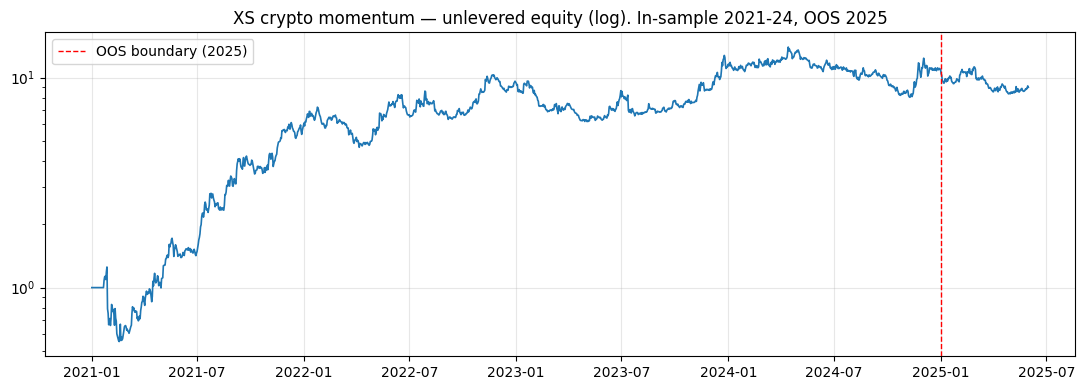

In-sample 2021-24 Sharpe 1.05 | 2025-OOS Sharpe -0.74


In [7]:
# equity curve, log scale, with the OOS boundary marked
eq = (1+r).cumprod()
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(eq.index, eq.values, lw=1.2)
ax.axvline(pd.Timestamp('2025-01-01'), color='red', ls='--', lw=1, label='OOS boundary (2025)')
ax.set_yscale('log'); ax.set_title('XS crypto momentum — unlevered equity (log). In-sample 2021-24, OOS 2025')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
plt.savefig('xs_crypto_equity.png', dpi=90); plt.show()
print('In-sample 2021-24 Sharpe %.2f | 2025-OOS Sharpe %.2f' %
      (sharpe(r[:'2024-12-31']), sharpe(r['2025-01-01':])))

The verdict is unambiguous and **must not be glossed over**: in-sample (2021–24) looks good, but the
**genuinely out-of-sample 2025 is negative (Sharpe ≈ −0.7)**. A favourable Monte-Carlo pass-rate computed by
resampling 2021–24 would therefore be **misleading** — it samples a regime that has since ended.


<a id='7'></a>
## 7. Diagnosis — it's a regime bet on cross-sectional dispersion

The P&L of a market-neutral alt book depends on **return dispersion across coins**. When alts move independently
(high dispersion) the ranking has signal; when everything tracks BTC (low dispersion, "BTC-dominance regime") the
long and short legs move together and the thin momentum edge is swamped. We measure dispersion as the mean
cross-sectional standard deviation of hourly returns, and decompose the composite into its components per year.


In [8]:
ret_mat = feats['log_ret'].unstack('symbol')
disp = ret_mat.std(axis=1).resample('D').mean()
print('Cross-sectional return dispersion & per-signal Sharpe, by year:')
hdr = f'{"year":>5} {"dispersion%":>11} | {"reversal":>9} {"momentum":>9} {"funding":>8} {"composite":>10}'
print(hdr); print('-'*len(hdr))
sig_r = {s: xs_portfolio_returns(feats, n_each=5, hold_bars=24, spread_bps=0, signal_col=s)[0].dropna()
         for s in ['reversal','momentum','fund_signal','composite']}
for yr,s,e in [('2021','2021-01-01','2021-12-31'),('2022','2022-01-01','2022-12-31'),
               ('2023','2023-01-01','2023-12-31'),('2024','2024-01-01','2024-12-31'),
               ('2025','2025-01-01','2025-05-31')]:
    d = disp[s:e].mean()*100
    cols = [sharpe(sig_r[k][s:e]) for k in ['reversal','momentum','fund_signal','composite']]
    print(f'{yr:>5} {d:>11.3f} | {cols[0]:>+9.2f} {cols[1]:>+9.2f} {cols[2]:>+8.2f} {cols[3]:>+10.2f}')

Cross-sectional return dispersion & per-signal Sharpe, by year:
 year dispersion% |  reversal  momentum  funding  composite
-----------------------------------------------------------


 2021       1.002 |     -1.76     +2.05    +1.95      +2.06
 2022       0.538 |     +1.34     +1.13    -0.45      +1.86
 2023       0.424 |     +1.58     +0.71    +0.34      +2.15
 2024       0.504 |     -0.60     +0.32    -0.17      -0.35
 2025       0.460 |     +1.90     -0.51    +0.87      +1.46


**What the table shows.**
- **Dispersion** falls from ~1.0%/hr (2021) to ~0.4–0.5% (2023–25). Less cross-sectional spread → less to harvest.
- **Reversal** flips sign with regime (works in chaotic/bear 2022–23, hurts in trending 2021/2024).
- **Momentum** is the most stable but decays toward zero as dispersion compresses, and 2025 finishes the job.

So the edge is real but **conditional on a high-dispersion regime**. That is precisely the wrong dependency for a
challenge we must pass *now*, in a low-dispersion BTC-dominance market.


<a id='8'></a>
## 8. Verdict and Path B

**Verdict.** Free Binance data delivers genuinely new signals (signed flow, funding) that OHLC cannot. The
cross-sectional construction is mathematically sound and removes the naked-direction and leverage problems.
**But every signal we built on it is regime-dependent (needs cross-sectional dispersion), and the current
2024–25 BTC-dominance regime is its worst case** — confirmed by a negative true-OOS 2025. We will **not** trust
the in-sample 65% pass-rate.

**Path B — find a regime-agnostic signal.** Candidates that do *not* rely on alt dispersion:
1. **Funding harvest done right** — short the few highest-funding coins / long the few lowest, sized small; the
   payoff is the *funding cash flow itself*, largely independent of price-dispersion regime.
2. **Short-horizon (intraday) reversal** where even BTC-correlated coins still mean-revert around their own VWAP.
3. **A regime *gate*** on the momentum book (only trade when dispersion or falling-BTC-dominance says the edge is on).

Path B starts from a clean hypothesis and the same honest bar: **positive true-OOS, costs in, sized to the CFT
static-10% rule.** Infrastructure (`binance_loader`, `crypto_xs`, the FTMO/CFT evaluator) all carries over.
